# Tunisian Arabic-French Code-Switching Detection

## Token-level Language Identification in Tunisian Arabizi Texts

**Author:** Siwar Ben Younes
**Institution:** École Supérieure de la Statistique et de l’Analyse de l’Information (ESSAI)
**Academic Year:** 2026–2027

# 1. Problem Statement

## Introduction and Context
Digital communication in Tunisia frequently combines Tunisian Arabic, French, and other languages. Tunisian Arabic is often written in Arabizi, a transliteration that uses Latin letters and numbers to represent certain Arabic sounds. This writing style varies from speaker to speaker and from word to word, complicating its automatic processing.

This project studies token-level language identification in the TArC (Tunisian Arabish Corpus). It compares two sequence labeling approaches: a Conditional Random Field (CRF), which relies on hand-crafted features and neighboring word context, and XLM-RoBERTa, a multilingual Transformer-based model. The classes chosen for this experiment are Tunisian Arabic written in Arabizi and foreign words.

## Problem Definition
How can we automatically identify, in Tunisian texts written in Arabizi, tokens belonging to Tunisian Arabic and those belonging to a foreign language?

More specifically, this work aims to:
- Compare the performance of CRF and XLM-RoBERTa on this task;
- Determine the types of tokens each model correctly classifies or confuses;
- Examine the influence of context on word identification in code-switched sentences.

The comparison is based on training, validation, and test splits, and on token-level metrics, including precision, recall, macro F1, and accuracy.

## Dataset Source and Access

The project uses the **Tunisian Arabish Corpus (TArC)**, a semi-automatically annotated corpus of Tunisian Arabic written in Latin characters (Arabizi).
*   **Official Source / GitHub**: [eligugliotta/tarc](https://github.com/eligugliotta/tarc)
*   **Data Type**: Textual data collected from forums, social networks, blogs, and Tunisian rap lyrics.

---

## Brief State of the Art

Language identification in code-switched texts has traditionally been addressed by two families of approaches:
1.  **Statistical & Lexical Methods**: The use of language dictionaries, combined with Hidden Markov Models (HMM) or **Conditional Random Fields (CRF)**. These models (Lafferty et al., 2001) excel at using low-level features (character n-grams, local morphology, language suffixes) and require very few computational resources.
2.  **Pre-trained Language Models (Transformers)**: Architectures like **mBERT** or **XLM-RoBERTa** (Conneau et al., 2020) have revolutionized token labeling tasks (Token Classification). Trained on massive volumes of multilingual texts, these models capture rich long-range contextual dependencies, although they are sometimes limited by subword tokenization (SentencePiece) on non-standardized or informal dialects like Arabizi.

# 2. Data (Acquisition, Exploration, and Preparation)## Dependencies and Environment SetupFrom the repository root, install all project dependencies with:```bashpip install -r requirements.txt```If the notebook is opened from the `notebooks` directory, run the following cell if needed.

In [3]:
%pip install -r ../requirements.txt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.2 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


## 1. Environment Preparation

Importing libraries used for data manipulation, result visualization, and model training.

In [4]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score
)

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

## Acquisition and Loading of the TArC Corpus

In [5]:
!git clone https://github.com/eligugliotta/tarc.git

Cloning into 'tarc'...
remote: Enumerating objects: 145, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 145 (delta 4), reused 11 (delta 3), pack-reused 129 (from 1)
Receiving objects: 100% (145/145), 1.91 MiB | 23.27 MiB/s, done.
Resolving deltas: 100% (55/55), done.


## 3. Verifying Available Files

In [6]:
import os

os.listdir("tarc")

['.git',
 'README.md',
 'rap.tab',
 'social.tab',
 'Multi_Task_Relations_LDK2023_presentation.pdf',
 'blog.tab',
 'Linguistic_Analyses',
 'forum.tab',
 'tarc.tsv']

## 4. Inspecting a Raw File

We display a few lines to check the separator, fields, and sentence structure before loading.

In [7]:
with open("tarc/social.tab", "r", encoding="utf-8") as f:
    for _ in range(20):
        print(repr(f.readline()))

'data\tarabish\tclass\tCODA\ttoken\tpos\tlemma\tgovernorate\tage\tgender\n'
'20150301\tR7\tforeign\tR7\tforeign\tforeign\tforeign\t/\t35-50\tF\n'
'20150301\tpatee\tarabizi\tباتي\tباتي\tNOUN\tباتي\t/\t35-50\tF\n'
'20150301\tdieri\tarabizi\tدياري\tدياري\tADJ\tدياري\t/\t35-50\tF\n'
'20150301\tw\tarabizi\tو\tو\tCONJ\tو\t/\t35-50\tF\n'
'20150301\tbniiiiiiiiiinnnn\tarabizi\tبنين\tبنين\tADJ\tبنين\t/\t35-50\tF\n'
'20150301\trecette\tforeign\trecette\tforeign\tforeign\tforeign\t/\t35-50\tF\n'
'20150301\t:\tarabizi\t:\t:\tPUNC\tPUNC\t/\t35-50\tF\n'
'\n'
'20150301\t3\tarabizi\t3\t3\tNOUN_NUM\tNOUN_NUM\t/\t35-50\tF\n'
'20150301\tkissen\tarabizi\tكيسان\tكيسان\tNOUN\tكاس\t/\t35-50\tF\n'
'20150301\tfarine\tforeign\tfarine\tforeign\tforeign\tforeign\t/\t35-50\tF\n'
'20150301\t+\tarabizi\t+\t+\tSYM\tSYM\t/\t35-50\tF\n'
'20150301\tkes\tarabizi\tكاس\tكاس\tNOUN\tكاس\t/\t35-50\tF\n'
'20150301\t7lib\tarabizi\tحليب\tحليب\tNOUN\tحليب\t/\t35-50\tF\n'
'20150301\t+\tarabizi\t+\t+\tSYM\tSYM\t/\t35-50\tF\n'
'20150

### Dataset Description

The corpus is a set of tab-separated values (TSV) files containing Tunisian Arabic written in **Arabizi**, foreign words, and linguistic annotations.

| Column | Description |
|---|---|
| `data` | Date or document ID |
| `arabish` | Original word form |
| `class` | Linguistic category, notably `arabizi` or `foreign` |
| `CODA` | Normalized form in Arabic script |
| `token` | Segmented or normalized token for analysis |
| `pos` | Part-of-speech tag |
| `lemma` | Word lemma |
| `governorate` | Governorate associated with the speaker |
| `age` | Age range |
| `gender` | Gender indicated in metadata |

**Examples:** `7lib` corresponds to "حليب" in Tunisian Arabic; `recette` and `farine` are French words. The `class` column provides the target label used to distinguish Arabizi tokens from foreign tokens.

## 5. Defining the File Reader

The following function reads the corpus format, retains useful annotations, and assigns an identifier to sentences.

In [8]:
def load_tarc_file(filepath, source_name):
    rows = []

    with open(filepath, "r", encoding="utf-8") as f:
        lines = f.readlines()

    header = None
    sentence_id = 0

    for line in lines:
        line = line.rstrip("\n")

        # Skip empty lines
        if not line.strip():
            sentence_id += 1
            continue

        # Header
        if line.startswith("data"):
            header = line.split("\t")
            continue

        parts = line.split("\t")

        if header is not None and len(parts) == len(header):
            row = dict(zip(header, parts))
            row["sentence_id"] = sentence_id
            row["source"] = source_name
            rows.append(row)

    return pd.DataFrame(rows)

## 6. Loading and Merging Sources

Forum, social media, blog, and rap lyric files are combined into a single DataFrame. The `source` column allows retaining the origin of each observation.

In [9]:
forum = load_tarc_file("tarc/forum.tab", "forum")
social = load_tarc_file("tarc/social.tab", "social")
blog = load_tarc_file("tarc/blog.tab", "blog")
rap = load_tarc_file("tarc/rap.tab", "rap")

df = pd.concat(
    [forum, social, blog, rap],
    ignore_index=True
)


## 7. Overview of the Merged Corpus

In [10]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst rows:")
display(df.head())

Shape: (43328, 12)

Columns:
['data', 'arabish', 'class', 'CODA', 'token', 'pos', 'lemma', 'governorate', 'age', 'gender', 'sentence_id', 'source']

First rows:


,data,arabish,class,CODA,token,pos,lemma,governorate,age,gender,sentence_id,source
0,20150902,3rabfieurope2011:,arabizi,عرب في اوروبا 2011 :,عرب+في+اوروبا+2011+:,NOUN+PREP+NOUN_PROP+NOUN_NUM+PUNC,عربي,Bizerte,25-35,M,0,forum
1,20150902,kifech,arabizi,كيفاش,كيفاش,INTERROG_ADV,كيفاش,Bizerte,25-35,M,0,forum
2,20150902,tchoufou,arabizi,تشوفوا,تشوفوا,IV2P-IV-IVSUFF_SUBJ:P,شاف,Bizerte,25-35,M,0,forum
3,20150902,l3icha,arabizi,العيشة,ال+عيشة,DET+NOUN-NSUFF_FEM_SG,عيشة,Bizerte,25-35,M,0,forum
4,20150902,fi8al,arabizi,فال,في+ال,PREP+DET,في,Bizerte,25-35,M,0,forum


### Column Structure and Types

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43328 entries, 0 to 43327
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   data         43328 non-null  object
 1   arabish      43328 non-null  object
 2   class        43328 non-null  object
 3   CODA         43328 non-null  object
 4   token        43328 non-null  object
 5   pos          43328 non-null  object
 6   lemma        43328 non-null  object
 7   governorate  43328 non-null  object
 8   age          43328 non-null  object
 9   gender       43328 non-null  object
 10  sentence_id  43328 non-null  int64 
 11  source       43328 non-null  object
dtypes: int64(1), object(11)
memory usage: 4.0+ MB


### Label Distribution

This distribution shows the number of tokens per category and helps identify any class imbalance.

In [12]:
df["class"].value_counts()

,count
class,
arabizi,31498
foreign,11212
emotag,617
nan,1


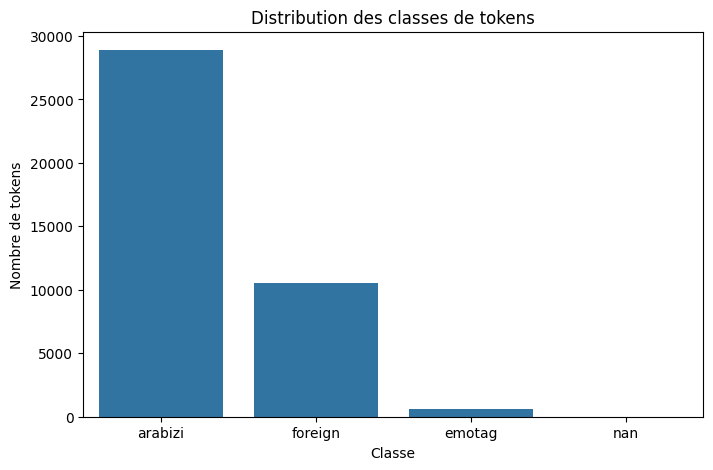

In [65]:
# Plot and save class distribution
plt.figure(figsize=(8, 5))
sns.barplot(x=df["class"].value_counts().index, y=df["class"].value_counts().values)
plt.title("Distribution des classes de tokens")
plt.xlabel("Classe")
plt.ylabel("Nombre de tokens")
plt.savefig("class_distribution.png")
plt.show()

### Number of Sentences per Source

In [13]:
sentence_counts = df.groupby("source")["sentence_id"].nunique()

sentence_counts

,sentence_id
source,
blog,366
forum,755
rap,515
social,3162


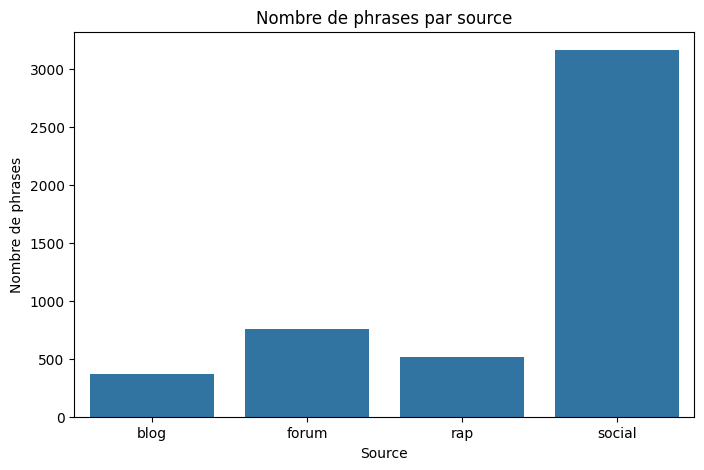

In [66]:
# Plot and save source distribution
plt.figure(figsize=(8, 5))
sns.barplot(x=sentence_counts.index, y=sentence_counts.values)
plt.title("Nombre de phrases par source")
plt.xlabel("Source")
plt.ylabel("Nombre de phrases")
plt.savefig("source_distribution.png")
plt.show()

### Examples of Tokens for Each Class

In [14]:
for label in df["class"].unique():
    print("\nCLASS:", label)
    display(
        df[df["class"] == label][["arabish", "class"]]
        .head(20)
    )


CLASS: arabizi


,arabish,class
0,3rabfieurope2011:,arabizi
1,kifech,arabizi
2,tchoufou,arabizi
3,l3icha,arabizi
4,fi8al,arabizi
5,5orba,arabizi
6,?,arabizi
7,Ena,arabizi
8,berjoulia,arabizi
9,kont,arabizi



CLASS: foreign


,arabish,class
13,mais,foreign
37,révolution,foreign
52,mais,foreign
60,Justement,foreign
73,ou,foreign
74,bien,foreign
77,puisk,foreign
79,les,foreign
80,dictateurs,foreign
106,bravo,foreign



CLASS: emotag


,arabish,class
104,:),emotag
150,<3,emotag
250,:),emotag
2151,:\,emotag
2152,:\,emotag
6027,#NAME?,emotag
6626,-->,emotag
6638,#ERROR!,emotag
9714,;),emotag
9989,:(,emotag



CLASS: nan


,arabish,class
24718,yarhmek,nan


### Most Frequent Tokens by Class

In [15]:
for label in df["class"].unique():
    tokens = (
        df[df["class"] == label]["arabish"]
        .astype(str)
        .str.lower()
    )

    print(f"\nTop tokens for {label}:")
    print(tokens.value_counts().head(20))


Top tokens for arabizi:
arabish
,       1288
w        919
el       627
fi       419
.        416
:        294
wou      218
...      190
al       185
ya       178
/        176
ma       162
kol      130
ki       130
men      129
?        128
ou       125
b        118
l        116
elli     110
Name: count, dtype: int64

Top tokens for foreign:
arabish
de      292
les     221
la      220
et      215
le      169
pas     147
je      132
à       129
\'      117
a       116
des     113
pour    102
est     100
en       96
que      92
c        90
un       82
il       80
mais     75
prix     70
Name: count, dtype: int64

Top tokens for emotag:
arabish
😂😂                                                             54
😂😂😂                                                            41
😂                                                              33
***********************************************************    17
🤣🤣                                                             12
😂😂😂😂                

### Missing Values

This check indicates whether any columns contain missing annotations.

In [16]:
print("Missing values:")
print(df.isna().sum())

Missing values:
data           0
arabish        0
class          0
CODA           0
token          0
pos            0
lemma          0
governorate    0
age            0
gender         0
sentence_id    0
source         0
dtype: int64


### Duplicate Rows

We measure duplicates before removing them to avoid counting the same observations multiple times.

In [17]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 3333


In [18]:
df = df.drop_duplicates().reset_index(drop=True)

## 8. Selecting Useful Columns

We retain the information necessary for classification, sentence reconstruction, and linguistic analysis.

In [19]:
data = df[[
    "sentence_id",
    "source",
    "arabish",
    "class",
    "pos",
    "lemma"
]].copy()

data.head()

,sentence_id,source,arabish,class,pos,lemma
0,0,forum,3rabfieurope2011:,arabizi,NOUN+PREP+NOUN_PROP+NOUN_NUM+PUNC,عربي
1,0,forum,kifech,arabizi,INTERROG_ADV,كيفاش
2,0,forum,tchoufou,arabizi,IV2P-IV-IVSUFF_SUBJ:P,شاف
3,0,forum,l3icha,arabizi,DET+NOUN-NSUFF_FEM_SG,عيشة
4,0,forum,fi8al,arabizi,PREP+DET,في


### Filtering Classes and Creating Numerical Labels

The two classes studied are retained: `arabizi` (0) and `foreign` (1).

In [20]:
data = data[data["class"].isin(["arabizi", "foreign"])].copy()

data["label"] = data["class"].map({
    "arabizi": 0,
    "foreign": 1
})

data.head()

,sentence_id,source,arabish,class,pos,lemma,label
0,0,forum,3rabfieurope2011:,arabizi,NOUN+PREP+NOUN_PROP+NOUN_NUM+PUNC,عربي,0
1,0,forum,kifech,arabizi,INTERROG_ADV,كيفاش,0
2,0,forum,tchoufou,arabizi,IV2P-IV-IVSUFF_SUBJ:P,شاف,0
3,0,forum,l3icha,arabizi,DET+NOUN-NSUFF_FEM_SG,عيشة,0
4,0,forum,fi8al,arabizi,PREP+DET,في,0


### Correspondence Between Class Names and IDs

These dictionaries ensure consistent conversion between human-readable labels and the IDs expected by the models.

In [21]:
label_names = [
    "Tunisian",
    "Foreign"
]

label2id = {
    "Tunisian": 0,
    "Foreign": 1
}

id2label = {
    0: "Tunisian",
    1: "Foreign"
}

### Token Normalization

Cleaning remains conservative to preserve numbers and apostrophes used in Arabizi, while discarding irrelevant characters.

In [22]:
import re
import unicodedata
import pandas as pd

def clean_arabizi(text):
    """
    Nettoyage conservateur de l'Arabizi tunisien.

    On conserve :
    - lettres latines
    - chiffres Arabizi (3, 5, 7, 9, ...)
    - apostrophes utiles
    - caractères arabes si présents
    """

    if pd.isna(text):
        return ""

    text = str(text)

    # 0. Convertir en minuscules dès le début
    text = text.lower()

    # 1. Normalisation Unicode
    text = unicodedata.normalize("NFKC", text)

    # 2. Suppression des URLs
    text = re.sub(
        r'https?://\S+|www\.\S+',
        ' ',
        text,
        flags=re.IGNORECASE
    )

    # 3. Suppression des emails
    text = re.sub(
        r'\b[\w.+-]+@[\w-]+\.[\w.-]+\b',
        ' ',
        text
    )

    # 4. Remplacement des retours à la ligne / tabulations
    text = re.sub(r'[\n\r\t]+', ' ', text)

    # 5. Réduction des espaces multiples
    text = re.sub(r'\s+', ' ', text)

    # 6. Réduction des répétitions excessives
    # Exemple :
    # beeeeeeh -> beeh
    # looooool -> lool
    #
    # On limite à 2 répétitions consécutives
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # 7. Suppression des caractères de contrôle
    text = ''.join(
        char for char in text
        if unicodedata.category(char) != 'Cc'
    )

    # 8. Nettoyage des caractères spéciaux inutiles
    # IMPORTANT : les chiffres sont CONSERVÉS
    text = re.sub(
        r'[^\w\s\u0600-\u06FF\'’-]',
        ' ',
        text,
        flags=re.UNICODE
    )

    # 9. Nettoyage final des espaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [23]:
data["token"] = data["arabish"].apply(clean_arabizi)

## 9. Sentence Reconstruction

Tokens are grouped by their source and sentence ID. This step is necessary to train and evaluate models that leverage sequential context.

In [24]:
sentences = (
    data.groupby(["source", "sentence_id"])
        .agg({
            "token": list,
            "label": list,
            "class": list,
            "pos": list,
            "lemma": list
        })
        .reset_index()
)

sentences.head()

,source,sentence_id,token,label,class,pos,lemma
0,blog,0,"[yebda, ki, jit, nek, ]","[0, 0, 0, 0, 0]","[arabizi, arabizi, arabizi, arabizi, arabizi]","[IV3MS-IV, SUB_CONJ, PV-PVSUFF_SUBJ:1S, IV1S-I...","[بدا, كي, جا, نك, PUNC]"
1,blog,1,"[teb, fi, ma9ali, hedha, janbi, 7akni, wou, so...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[arabizi, arabizi, arabizi, arabizi, arabizi, ...","[CONJ, PREP, REL_PRON+PV-PVSUFF_SUBJ:3MS+[PREP...","[طاب, في, قال, هاذا, جنب, حكّ, و, صبع, ال, صغي..."
2,blog,2,"[wou, chadetni, el, gafguéfa, labni, la3ra9, ]","[0, 0, 0, 0, 0, 0, 0]","[arabizi, arabizi, arabizi, arabizi, arabizi, ...","[CONJ, PV-PVSUFF_SUBJ:3FS+PVSUFF_DO:1S, DET, N...","[و, شدّ, ال, ڨفڨافة, لب, عرق, PUNC]"
3,blog,3,"[wou, talla3et, ma, habbat, ]","[0, 0, 0, 0, 0]","[arabizi, arabizi, arabizi, arabizi, arabizi]","[CONJ, PV-PVSUFF_SUBJ:1S, NEG_PART, PV-PVSUFF_...","[و, طلّع, ما, هبط, PUNC]"
4,blog,4,"[3ad, 9olet, 5alini, nekteb, , ena, hakkeka, w...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[arabizi, arabizi, arabizi, arabizi, arabizi, ...","[CONJ, PV-PVSUFF_SUBJ:1S, CV2S-CV+CVSUFF_DO:1S...","[عاد, قال, خلّى, كتب, PUNC, هو, هكاكا, و, دار,..."


### Examples of Reconstructed Sentences

In [25]:
for _, row in sentences.head(10).iterrows():
    print(" ".join(row["token"]))

yebda ki jit nek 
teb fi ma9ali hedha janbi 7akni wou sob3 el sghir 9rasni 3ini dam3et 9albi walla ydo9  mel far7a 
wou chadetni el gafguéfa labni la3ra9 
wou talla3et ma habbat 
3ad 9olet 5alini nekteb  ena hakkeka wou dar el bab jari elli yosken m9abelni 7alitlou beb le7ya ghoufa men 3am areb3a 
labes jelbeb wou 3ara9iya barnous m9amet fi jed ommou 
msawek fommou wou mka7el 3inih mbal7et le7ytou bel 7enna ghzarli 9ali amir el mo2  mini ja 
wou bda y kabber wa77ed  salli 3al nib 3awed 9otlou ya weldi rahou bech yet9arra3lek 3ere9 9ali 5alini ana tawa fi nachwa m3a rou7i
 9otlou ya weldi amir el mo2minin  mouch mat wou chba3 mout sa5ta 9ali a3dhou bel leha wou achreb mah  yezzi rajjel rja3tou bima 100 sna tali
wallitou tawa mo3tasmin bi7abel el lah wou tsaliwou jama3a  labastou mra 9ortass chayebtou rass 3alem fa9ih


### Identifying Code-Switched Sentences

A sentence is considered code-switched if it contains at least one token from each of the two classes.

In [26]:
def is_code_switched(labels):
    return len(set(labels)) > 1

sentences["code_switched"] = sentences["label"].apply(is_code_switched)

sentences["code_switched"].value_counts()

,count
code_switched,
False,3066
True,1690


## 10. Data Splitting

Sentences are divided into training, validation, and test sets. The split is stratified by the presence of code-switching to maintain comparable proportions.

In [27]:
train_sent, test_sent = train_test_split(
    sentences,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=sentences["code_switched"]
)

train_sent, val_sent = train_test_split(
    train_sent,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=train_sent["code_switched"]
)

print("Train sentences:", len(train_sent))
print("Validation sentences:", len(val_sent))
print("Test sentences:", len(test_sent))

Train sentences: 3435
Validation sentences: 607
Test sentences: 714


**Training:** Used to adjust model parameters.

**Validation:** Used to compare configurations and guide tuning choices.

**Test:** Used to estimate final performance once decisions are made. It should not guide training.

### Transition from Sentence Level to Token Level

For diagnostics and certain metrics, partitioned sentences are also represented as individual token-level rows.

In [28]:
def explode_sentences(sentence_df):
    rows = []

    for _, row in sentence_df.iterrows():
        for token, label in zip(row["token"], row["label"]):
            rows.append({
                "source": row["source"],
                "sentence_id": row["sentence_id"],
                "token": token,
                "label": label
            })

    return pd.DataFrame(rows)

train_tokens = explode_sentences(train_sent)
val_tokens = explode_sentences(val_sent)
test_tokens = explode_sentences(test_sent)

print(train_tokens.shape)
print(val_tokens.shape)
print(test_tokens.shape)

(28421, 4)
(5393, 4)
(5592, 4)


### Verifying No Data Leakage Between Partitions

We compare the sentence IDs of the training, validation, and test sets. A sentence should only appear in one partition.

In [29]:
train_ids = set(zip(train_sent["source"], train_sent["sentence_id"]))
val_ids   = set(zip(val_sent["source"], val_sent["sentence_id"]))
test_ids  = set(zip(test_sent["source"], test_sent["sentence_id"]))

print("Train-Val overlap:", len(train_ids & val_ids))
print("Train-Test overlap:", len(train_ids & test_ids))
print("Val-Test overlap:", len(val_ids & test_ids))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


# 3. Methodology

In this section, we define the two theoretical approaches to solve the sequence tagging problem applied to code-switching.

### 3.1. Statistical Approach: Conditional Random Fields (CRF)
CRF is a discriminative probabilistic model for sequence tagging. Unlike standard classifiers, it models the global conditional distribution $P(Y|X)$ over the entire sequence of labels given the input sequence, thus capturing transition dependencies between adjacent classes.

### 3.2. Deep Learning Approach: XLM-RoBERTa
XLM-RoBERTa is a Transformer-based masked language model, pre-trained on very large multilingual corpora. It provides rich contextualized representations for each token, allowing us to fine-tune a linear classification layer (Token Classification) on top of the base model.

---

# 4. Model Implementation

## 4.1. CRF Model Implementation

### Preparing Sequences for CRF

Each sentence becomes a sequence of tuples containing the token, its part-of-speech tag, its lemma, and its target label.

In [30]:
def create_crf_sentences(df):
    crf_sents = []

    for _, row in df.iterrows():

        sentence = []

        for token, pos, lemma, label in zip(
            row['token'],
            row['pos'],
            row['lemma'],
            row['label']
        ):
            sentence.append(
                (
                    str(token),
                    str(pos),
                    str(lemma),
                    str(label)
                )
            )

        crf_sents.append(sentence)

    return crf_sents


crf_train_sents = create_crf_sentences(train_sent)
crf_val_sents   = create_crf_sentences(val_sent)
crf_test_sents  = create_crf_sentences(test_sent)

### Feature Engineering

The following functions describe each token based on its form, prefixes and suffixes, annotations, and local context.

In [31]:
import re

def word2features(sent, i):
    word = sent[i][0]

    features = {
        # -------------------------
        # Token
        # -------------------------
        'bias': 1.0,
        'word.lower()': word.lower(),
        'word[-3:]': word[-3:],
        'word[-2:]': word[-2:],
        'word[:2]': word[:2],
        'word[:3]': word[:3],

        # -------------------------
        # Forme du mot
        # -------------------------
        'word.isupper()': word.isupper(),
        'word.istitle()': word.istitle(),
        'word.isdigit()': word.isdigit(),

        # -------------------------
        # Arabizi
        # -------------------------
        'word.has_digit': bool(re.search(r'\d', word)),
        'word.has_apostrophe': "'" in word,
        'word.length': len(word),
    }

    # =========================
    # Previous token
    # =========================
    if i > 0:
        word1 = sent[i-1][0]
        features.update({
            '-1:word.lower()': word1.lower(),
            '-1:word.istitle()': word1.istitle(),
            '-1:word.isupper()': word1.isupper(),
            '-1:has_digit': bool(re.search(r'\d', word1)),
        })
    else:
        features['BOS'] = 1.0

    # =========================
    # Next token
    # =========================
    if i < len(sent) - 1:
        word1 = sent[i+1][0]
        features.update({
            '+1:word.lower()': word1.lower(),
            '+1:word.istitle()': word1.istitle(),
            '+1:word.isupper()': word1.isupper(),
            '+1:has_digit': bool(re.search(r'\d', word1)),
        })
    else:
        features['EOS'] = 1.0

    return features

In [32]:
def sent2features(sent):
    return [
        word2features(sent, i)
        for i in range(len(sent))
    ]

def sent2labels(sent):
    return [
        label
        for token, pos, lemma, label in sent
    ]

def sent2tokens(sent):
    return [
        token
        for token, pos, lemma, label in sent
    ]

In [33]:
# Ré-extraction des caractéristiques sans fuite d'informations
X_train = [sent2features(s) for s in crf_train_sents]
y_train = [sent2labels(s) for s in crf_train_sents]

X_val = [sent2features(s) for s in crf_val_sents]
y_val = [sent2labels(s) for s in crf_val_sents]

X_test = [sent2features(s) for s in crf_test_sents]
y_test = [sent2labels(s) for s in crf_test_sents]

print("Caractéristiques ré-extraites avec succès.")

Caractéristiques ré-extraites avec succès.


In [34]:
print("Train labels:",
      set(label for sent in y_train for label in sent))

print("Validation labels:",
      set(label for sent in y_val for label in sent))

print("Test labels:",
      set(label for sent in y_test for label in sent))

Train labels: {'1', '0'}
Validation labels: {'1', '0'}
Test labels: {'1', '0'}


### CRF Training

The model is fitted on the training sentences. Regularization parameters limit the model's complexity.

In [35]:
# Ré-entraînement du modèle CRF sur les caractéristiques nettoyées
import sklearn_crfsuite

crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    c1=0.1,
    c2=0.1,
    max_iterations=100,
    all_possible_transitions=True
)

crf.fit(X_train, y_train)

CRF(algorithm='lbfgs', all_possible_transitions=True, c1=0.1, c2=0.1,
    max_iterations=100)

### CRF Evaluation

Performance is first examined on the validation set, then calculated on the test set to produce a final estimate.

In [36]:
# Ré-évaluation du modèle CRF sur le jeu de validation nettoyé
from sklearn_crfsuite import metrics

y_val_pred = crf.predict(X_val)

y_val_converted = [[id2label[int(label)] for label in sent] for sent in y_val]
y_val_pred_converted = [[id2label[int(label)] for label in sent] for sent in y_val_pred]

print(
    metrics.flat_classification_report(
        y_val_converted,
        y_val_pred_converted,
        labels=label_names,
        digits=4
    )
)

              precision    recall  f1-score   support

    Tunisian     0.9753    0.9876    0.9814      3874
     Foreign     0.9673    0.9361    0.9515      1519

    accuracy                         0.9731      5393
   macro avg     0.9713    0.9619    0.9664      5393
weighted avg     0.9730    0.9731    0.9730      5393



In [37]:
y_test_pred = crf.predict(X_test)

In [38]:
from sklearn.metrics import classification_report

# Aplatir y_test pour obtenir une seule liste de labels réels sous forme d'entiers
y_test_flat = [int(label) for phrase in y_test for label in phrase]

# Aplatir y_test_pred pour obtenir une seule liste de labels prédits sous forme d'entiers
y_pred_flat = [int(label) for phrase in y_test_pred for label in phrase]

print("\n===== CLASSIFICATION REPORT — TEST (CRF) =====\n")

print(
    classification_report(
        y_test_flat,
        y_pred_flat,
        labels=[0, 1],
        target_names=label_names,
        digits=4
    )
)


===== CLASSIFICATION REPORT — TEST (CRF) =====

              precision    recall  f1-score   support

    Tunisian     0.9755    0.9854    0.9804      4116
     Foreign     0.9582    0.9309    0.9443      1476

    accuracy                         0.9710      5592
   macro avg     0.9668    0.9582    0.9624      5592
weighted avg     0.9709    0.9710    0.9709      5592



In [39]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Ensure y_test_flat and y_pred_flat are lists of integers for metric calculation
y_true_crf = [int(label) for label in y_test_flat]
y_pred_crf = [int(label) for label in y_pred_flat]

test_accuracy = accuracy_score(y_true_crf, y_pred_crf)
test_precision = precision_score(y_true_crf, y_pred_crf, average='macro', zero_division=0)
test_recall = recall_score(y_true_crf, y_pred_crf, average='macro', zero_division=0)
test_f1 = f1_score(y_true_crf, y_pred_crf, average='macro', zero_division=0)

print(f"CRF Test Accuracy: {test_accuracy:.4f}")
print(f"CRF Test Precision (macro): {test_precision:.4f}")
print(f"CRF Test Recall (macro): {test_recall:.4f}")
print(f"CRF Test F1-score (macro): {test_f1:.4f}")

CRF Test Accuracy: 0.9710
CRF Test Precision (macro): 0.9668
CRF Test Recall (macro): 0.9582
CRF Test F1-score (macro): 0.9624


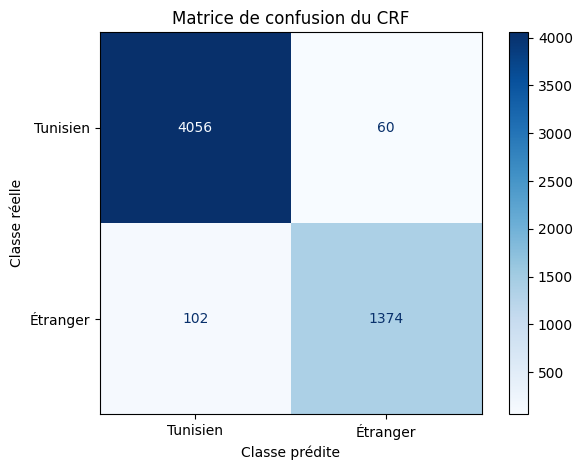

In [69]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Aplatir les étiquettes des phrases en une seule liste
y_true = [int(label) for phrase in y_test for label in phrase]
y_pred = [int(label) for phrase in y_test_pred for label in phrase]

# Matrice de confusion
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Tunisien", "Étranger"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion du CRF")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.tight_layout()
plt.savefig("confusion_matrix_crf.png")
plt.show()

## 4.2. XLM-RoBERTa Model Implementation

### Converting Sentences to Hugging Face Format

Each example contains a list of tokens and the corresponding list of numerical labels.

In [41]:
from datasets import Dataset

def create_hf_dataset(sentence_df):
    records = []

    for _, row in sentence_df.iterrows():
        records.append({
            "tokens": row["token"],
            "ner_tags": row["label"]
        })

    return Dataset.from_list(records)

train_dataset = create_hf_dataset(train_sent)
val_dataset = create_hf_dataset(val_sent)
test_dataset = create_hf_dataset(test_sent)

train_dataset

Dataset({
    features: ['tokens', 'ner_tags'],
    num_rows: 3435
})

### Loading the Tokenizer

In [42]:
from transformers import AutoTokenizer

model_checkpoint = "xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(
    model_checkpoint
)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

### Tokenization and Label Alignment

The tokenizer can split a token into multiple sub-tokens. The function aligns labels to these sub-tokens and ignores special positions when calculating the loss.

In [43]:
def tokenize_and_align_labels(examples):
    tokenized_inputs = tokenizer(
        examples["tokens"],
        truncation=True,
        padding="max_length",
        is_split_into_words=True,
        max_length=128
    )

    all_labels = []

    for i, labels in enumerate(examples["ner_tags"]):
        word_ids = tokenized_inputs.word_ids(batch_index=i)

        previous_word_idx = None
        label_ids = []

        for word_idx in word_ids:

            if word_idx is None:
                label_ids.append(-100)

            elif word_idx != previous_word_idx:
                label_ids.append(labels[word_idx])

            else:
                # Ignore additional subword pieces
                label_ids.append(-100)

            previous_word_idx = word_idx

        all_labels.append(label_ids)

    tokenized_inputs["labels"] = all_labels

    return tokenized_inputs

### Applying Tokenization to Partitions

In [44]:
tokenized_train = train_dataset.map(
    tokenize_and_align_labels,
    batched=True
)

tokenized_val = val_dataset.map(
    tokenize_and_align_labels,
    batched=True
)

tokenized_test = test_dataset.map(
    tokenize_and_align_labels,
    batched=True
)

Map:   0%|          | 0/3435 [00:00<?, ? examples/s]

Map:   0%|          | 0/607 [00:00<?, ? examples/s]

Map:   0%|          | 0/714 [00:00<?, ? examples/s]

### Initializing the Token Classification Model

The classification head is configured with the two previously defined classes.

In [45]:
from transformers import AutoModelForTokenClassification

model = AutoModelForTokenClassification.from_pretrained(
    model_checkpoint,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### Defining Metrics

Metrics are calculated at the sequence level, ignoring positions masked by alignment.

In [46]:
# Mettre à jour pip pour éviter les problèmes d'installation
!pip install --upgrade pip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 38.1 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2


In [47]:
# Installer `seqeval` qui est nécessaire pour les métriques
!pip install seqeval

  Using cached seqeval-1.2.2.tar.gz (43 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16251 sha256=751d9e7d07893d1393134bd65ce9a0ff3224c5422f35a24dbd9a5bf6e6742510
  Stored in directory: /root/.cache/pip/wheels/14/cf/a7/8f28ef376d707ff10e3922899482a2f23ef3002f8a952f47ac
Successfully built seqeval


In [48]:
import evaluate

seqeval_metric = evaluate.load("seqeval")

In [49]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=2)

    y_true, y_pred = [], []

    for pred_seq, label_seq in zip(predictions, labels):
        for pred, label in zip(pred_seq, label_seq):
            # Ignorer les tokens spéciaux, le padding et les sous-tokens masqués
            if label != -100:
                y_true.append(int(label))
                y_pred.append(int(pred))

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

### Training Configuration

The arguments specify the learning rate, batch size, and evaluation/save frequency.

In [50]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./xlmr-code-switching",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=1,
    weight_decay=0.01,
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    report_to="none"
)

In [51]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    processing_class=tokenizer,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics
)


### Starting Training

In [52]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.147069,0.101539,0.968438,0.966865,0.957242,0.961878


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=430, training_loss=0.16890225410461426, metrics={'train_runtime': 161.5405, 'train_samples_per_second': 21.264, 'train_steps_per_second': 2.662, 'total_flos': 224388589847040.0, 'train_loss': 0.16890225410461426, 'epoch': 1.0})

### Final Evaluation on the Test Set

The test set is used after training to measure the performance of the final model.

In [53]:
xlmr_results = trainer.evaluate(
    tokenized_test
)

xlmr_results

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.147069,0.121062,1,0.962977,0.958344,0.949251,0.953657


{'eval_loss': 0.1210620179772377,
 'eval_accuracy': 0.9629770267704576,
 'eval_precision': 0.9583443492225912,
 'eval_recall': 0.949250882313624,
 'eval_f1': 0.9536569963918367}

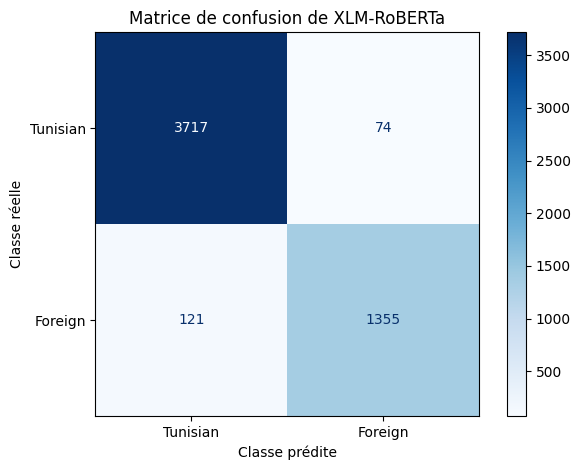

In [70]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# True and predicted labels for XLM-RoBERTa
y_true_xlmr = xlmr_test_tokens["label"].tolist()
y_pred_xlmr = xlmr_test_tokens["prediction"].tolist()

# Confusion Matrix
cm_xlmr = confusion_matrix(y_true_xlmr, y_pred_xlmr, labels=[0, 1])

disp_xlmr = ConfusionMatrixDisplay(
    confusion_matrix=cm_xlmr,
    display_labels=label_names # Using the same labels as CRF: "Tunisian", "Foreign"
)
disp_xlmr.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion de XLM-RoBERTa")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.tight_layout()
plt.savefig("confusion_matrix_xlmr.png")
plt.show()

# 5. Evaluation and Results

Here, we bring together the overall metrics obtained by CRF and XLM-RoBERTa on unseen test data during training to rigorously compare their identification performance.

In [54]:
results = pd.DataFrame({
    "Model": [
        "Conditional Random Field (CRF)",
        "XLM-RoBERTa"
    ],
    "Macro F1": [
        test_f1,
        xlmr_results["eval_f1"]
    ],
    "Accuracy": [
        test_accuracy,
        xlmr_results["eval_accuracy"]
    ],
    "Precision": [
        test_precision,
        xlmr_results["eval_precision"]
    ],
    "Recall": [
        test_recall,
        xlmr_results["eval_recall"]
    ]
})

display(results.sort_values("Macro F1", ascending=False))

,Model,Macro F1,Accuracy,Precision,Recall
0,Conditional Random Field (CRF),0.962375,0.971030,0.966814,0.958159
1,XLM-RoBERTa,0.953657,0.962977,0.958344,0.949251


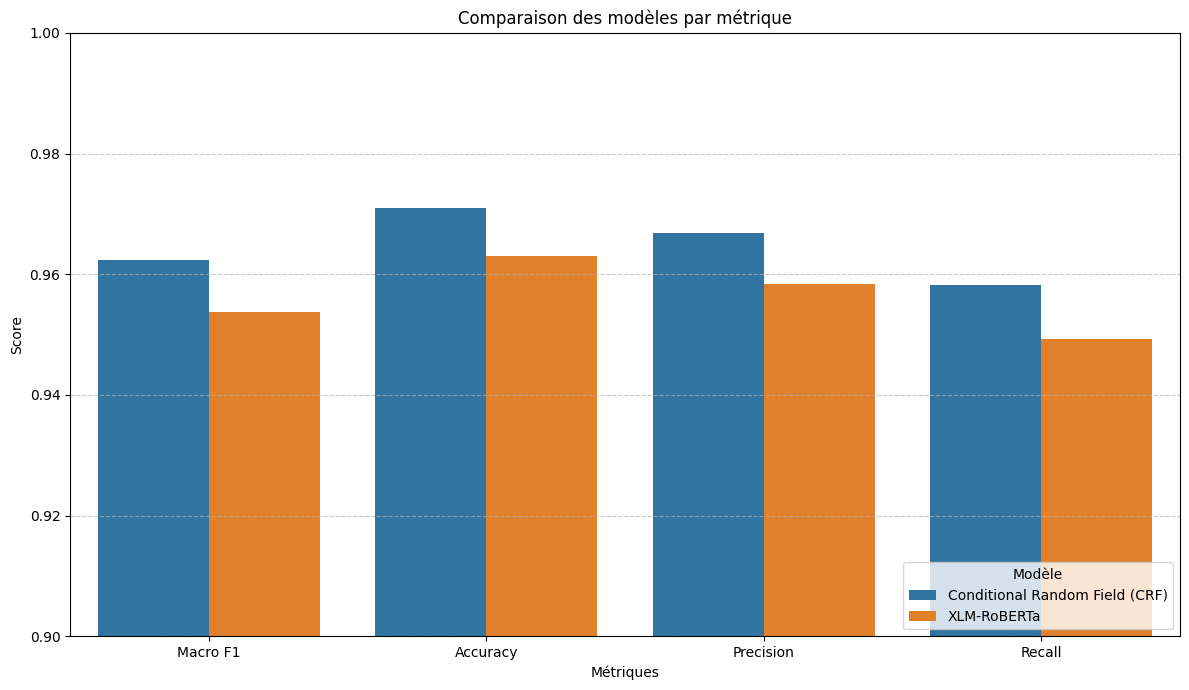

In [68]:
# Melt the results DataFrame to plot all metrics
results_melted = results.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 7))
sns.barplot(x="Metric", y="Score", hue="Model", data=results_melted)
plt.title("Comparaison des modèles par métrique")
plt.xlabel("Métriques")
plt.ylabel("Score")
plt.ylim(0.9, 1.0) # Set a relevant y-axis limit for scores close to 1
plt.legend(title="Modèle", loc="lower right")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()

# 6. Critical Analysis and Limitations

## 6.1. CRF Error Analysis

### Preparing Predictions and References

Test sequences are flattened to associate each prediction with the corresponding token.

In [55]:
# Flatten the list of lists for y_test_pred to match test_tokens
flat_y_test_pred = [label for sublist in y_test_pred for label in sublist]

# Convert predicted labels to integers for correct comparison
flat_y_test_pred_int = [int(label) for label in flat_y_test_pred]

# Create a DataFrame for error analysis
error_df = test_tokens.copy()
error_df["prediction"] = flat_y_test_pred_int

# Identify errors where true label != predicted label
errors = error_df[error_df["label"] != error_df["prediction"]].copy()

print("Aperçu des 30 premières erreurs:")
display(errors.head(30))

Aperçu des 30 premières erreurs:


,source,sentence_id,token,label,prediction
80,social,693,i_venture_to_discover,1,0
86,social,267,ll,0,1
164,rap,269,madfon,0,1
246,social,2509,m5abbi1264,1,0
363,social,383,marahbe,0,1
365,social,2558,allo,1,0
460,forum,385,sagon,1,0
489,blog,182,louage,0,1
491,blog,182,médenine,0,1
526,blog,239,s’il,1,0


### General Error Statistics

In [56]:
error_rate = len(errors) / len(test_tokens)

print(f"Taux d'erreur: {error_rate:.4f}")
print(f"Nombre d'erreurs: {len(errors)}")
print(f"Nombre total de tokens de test: {len(test_tokens)}")

Taux d'erreur: 0.0290
Nombre d'erreurs: 162
Nombre total de tokens de test: 5592


### False Positives and False Negatives

A false positive here corresponds to a foreign token predicted as Arabizi; a false negative corresponds to an Arabizi token predicted as foreign.

In [57]:
# Map numerical labels to descriptive class names
# Ensure that 'label' (string) is converted to int before using id2label
errors["true_class"] = errors["label"].astype(int).map(id2label)
# 'prediction' (int) can be directly mapped using id2label
errors["predicted_class"] = errors["prediction"].map(id2label)

print("Erreurs Foreign (Étranger) → Tunisian (Tunisien):")
display(
    errors[
        (errors["true_class"] == "Foreign") &
        (errors["predicted_class"] == "Tunisian")
    ]["token"]
    .value_counts()
    .head(20)
)

print("\nErreurs Tunisian (Tunisien) → Foreign (Étranger):")
display(
    errors[
        (errors["true_class"] == "Tunisian") &
        (errors["predicted_class"] == "Foreign")
    ]["token"]
    .value_counts()
    .head(20)
)


Erreurs Foreign (Étranger) → Tunisian (Tunisien):


,count
token,
pùb,2
sagon,2
el,2
__crazy__,2
m5abbi1264,1
i_venture_to_discover,1
ya,1
moyen,1
_ft_,1



Erreurs Tunisian (Tunisien) → Foreign (Étranger):


,count
token,
dog,2
ster,2
marahbe,1
louage,1
médenine,1
mekent,1
yaqter,1
dem,1
ll,1


### Examples of Sentences Containing Errors

Examples facilitate qualitative error examination by recontextualizing tokens.

In [58]:
error_tokens_set = set(errors["token"])

error_sentences = []

for _, row in test_sent.iterrows():
    sentence_tokens = row["token"]
    if any(token in error_tokens_set for token in sentence_tokens):
        error_sentences.append(" ".join(sentence_tokens))

print("Premières 20 phrases contenant des erreurs:")
for sentence in error_sentences[:20]:
    print(sentence)

Premières 20 phrases contenant des erreurs:
merci encore une fois
 i_venture_to_discover
bonjour ya jem3a chkoun mechi ll randonnée
ou weld flèn ki y7éb 5édmè juste yhéz telifoun 
2018 al rap wella qualité zéro mellime w te7kili 3la l’identité madfon ta7t ard homa f les posters l’artiste tawa 9ima ta3o f carte bancaire
 ya 7ammi el smaa 3lina wou 3lik 3amel fiha mitheli mithell mcha m3a emmalih
username  m5abbi1264
f loud  kel 3ada bnet esghar w nagzou cho hethi lo5ra  ba3d aux choses sérieuses habbet te5ou tsawer mel passerelle el m3allem ysou9
7ad me ya7ki 3al islem kolha ta7ki bism wataniye 
mé ça n'empèche  èni pour ce qui est mahdia en tant que blèd ni7i la3bèd jm bc 
t3ich lbara w theb tchi5 cart google play 15   marahbe bik
allo lelkol
ya m3aleem 5likom m7der 5iir vja3touni
mais à mahdia  malheureusement la3bed el behin représentent une minorité
oui fi beli biha hel accident mte3ou en fait le7e9 wra wa7ed bel moto ye5i d5el bih lessab5a ye55i sagon ta7 mouch behya echmeta
amin y

## 6.2. XLM-RoBERTa Error Analysis

In [59]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

# Calculer les prédictions du modèle sur le jeu de test
xlmr_prediction_output = trainer.predict(tokenized_test)
xlmr_prediction_ids = np.argmax(xlmr_prediction_output.predictions, axis=2)

# Relier chaque prédiction au token d'origine
xlmr_rows = []

for example_index, (_, row) in enumerate(test_sent.iterrows()):
    encoded = tokenizer(
        row["token"],
        truncation=True,
        padding="max_length",
        is_split_into_words=True,
        max_length=128
    )

    word_ids = encoded.word_ids()
    previous_word_id = None

    for subtoken_index, word_id in enumerate(word_ids):
        # Ignorer les tokens spéciaux, le remplissage et les sous-tokens supplémentaires
        if word_id is None or word_id == previous_word_id:
            continue

        previous_word_id = word_id

        xlmr_rows.append({
            "source": row["source"],
            "sentence_id": row["sentence_id"],
            "position": word_id,
            "sentence": " ".join(row["token"]),
            "token": row["token"][word_id],
            "label": int(row["label"][word_id]),
            "prediction": int(xlmr_prediction_ids[example_index][subtoken_index])
        })

xlmr_test_tokens = pd.DataFrame(xlmr_rows)
xlmr_test_tokens["true_class"] = xlmr_test_tokens["label"].map(id2label)
xlmr_test_tokens["predicted_class"] = xlmr_test_tokens["prediction"].map(id2label)

xlmr_errors = xlmr_test_tokens[
    xlmr_test_tokens["label"] != xlmr_test_tokens["prediction"]
].copy()

print(classification_report(
    xlmr_test_tokens["label"],
    xlmr_test_tokens["prediction"],
    labels=[0, 1],
    target_names=[id2label[0], id2label[1]],
    digits=4,
    zero_division=0
))

print(f"Nombre d'erreurs : {len(xlmr_errors)} / {len(xlmr_test_tokens)} tokens")
print(f"Taux d'erreur : {len(xlmr_errors) / max(len(xlmr_test_tokens), 1):.4f}")

display(xlmr_errors.head(30))

              precision    recall  f1-score   support

    Tunisian     0.9685    0.9805    0.9744      3791
     Foreign     0.9482    0.9180    0.9329      1476

    accuracy                         0.9630      5267
   macro avg     0.9583    0.9493    0.9537      5267
weighted avg     0.9628    0.9630    0.9628      5267

Nombre d'erreurs : 195 / 5267 tokens
Taux d'erreur : 0.0370


,source,sentence_id,position,sentence,token,label,prediction,true_class,predicted_class
3,social,258,1,manouba_club_camping,manouba_club_camping,1,0,Foreign,Tunisian
5,forum,544,0,merci encore une fois,merci,0,1,Tunisian,Foreign
56,rap,28,8,l7akem ilawéj l tawa zatla fil edoura marra to...,toura,0,1,Tunisian,Foreign
103,social,2823,4,date dimanche 3 mars 2019,mars,1,0,Foreign,Tunisian
150,rap,269,6,2018 al rap wella qualité zéro mellime w te7ki...,mellime,1,0,Foreign,Tunisian
229,social,2509,2,username m5abbi1264,m5abbi1264,1,0,Foreign,Tunisian
271,forum,324,0,mé ça n'empèche èni pour ce qui est mahdia en...,mé,1,0,Foreign,Tunisian
274,forum,324,4,mé ça n'empèche èni pour ce qui est mahdia en...,èni,0,1,Tunisian,Foreign
283,forum,324,13,mé ça n'empèche èni pour ce qui est mahdia en...,blèd,0,1,Tunisian,Foreign
286,forum,324,16,mé ça n'empèche èni pour ce qui est mahdia en...,jm,1,0,Foreign,Tunisian


In [60]:
print("Mots étrangers prédits comme tunisiens :")
display(
    xlmr_errors[
        (xlmr_errors["true_class"] == "Foreign") &
        (xlmr_errors["predicted_class"] == "Tunisian")
    ]["token"].value_counts().head(20)
)

print("Mots tunisiens prédits comme étrangers :")
display(
    xlmr_errors[
        (xlmr_errors["true_class"] == "Tunisian") &
        (xlmr_errors["predicted_class"] == "Foreign")
    ]["token"].value_counts().head(20)
)

Mots étrangers prédits comme tunisiens :


,count
token,
sagon,4
pùb,2
mé,2
frer,2
__crazy__,2
lool,2
el,2
koi,2
bc,1


Mots tunisiens prédits comme étrangers :


,count
token,
merci,4
ou,4
-,3
dt,3
l,3
star,2
normal,2
facebook,2
said,2


In [63]:
xlmr_error_rate = len(xlmr_errors) / len(xlmr_test_tokens)

print(f"Taux d'erreur (XLM-RoBERTa): {xlmr_error_rate:.4f}")
print(f"Nombre d'erreurs (XLM-RoBERTa): {len(xlmr_errors)}")
print(f"Nombre total de tokens de test (XLM-RoBERTa): {len(xlmr_test_tokens)}")

Taux d'erreur (XLM-RoBERTa): 0.0370
Nombre d'erreurs (XLM-RoBERTa): 195
Nombre total de tokens de test (XLM-RoBERTa): 5267


In [61]:
for _, row in xlmr_errors.drop_duplicates(
    ["source", "sentence_id"]
).head(20).iterrows():

    print(f"[{row['source']} / phrase {row['sentence_id']}] {row['sentence']}")

    phrase_errors = xlmr_errors[
        (xlmr_errors["source"] == row["source"]) &
        (xlmr_errors["sentence_id"] == row["sentence_id"])
    ]

    for _, erreur in phrase_errors.iterrows():
        print(
            f"  position {erreur['position']} : {erreur['token']!r} — "
            f"réel : {erreur['true_class']}, prédit : {erreur['predicted_class']}"
        )

[social / phrase 258]  manouba_club_camping
  position 1 : 'manouba_club_camping' — réel : Foreign, prédit : Tunisian
[forum / phrase 544] merci encore une fois
  position 0 : 'merci' — réel : Tunisian, prédit : Foreign
[rap / phrase 28] l7akem ilawéj l tawa zatla fil edoura marra toura foura rasi dar 
  position 8 : 'toura' — réel : Tunisian, prédit : Foreign
[social / phrase 2823] date  dimanche 3 mars 2019
  position 4 : 'mars' — réel : Foreign, prédit : Tunisian
[rap / phrase 269] 2018 al rap wella qualité zéro mellime w te7kili 3la l’identité madfon ta7t ard homa f les posters l’artiste tawa 9ima ta3o f carte bancaire
  position 6 : 'mellime' — réel : Foreign, prédit : Tunisian
[social / phrase 2509] username  m5abbi1264
  position 2 : 'm5abbi1264' — réel : Foreign, prédit : Tunisian
[forum / phrase 324] mé ça n'empèche  èni pour ce qui est mahdia en tant que blèd ni7i la3bèd jm bc 
  position 0 : 'mé' — réel : Foreign, prédit : Tunisian
  position 4 : 'èni' — réel : Tunisian, pré

## 6.3. Synthesis of Critical Analysis

Although both models achieve very high overall performance (F1-macro > 96%), a fine-grained error analysis reveals common and specific limitations:

1.  **Lexical Ambiguities and Context**:
    - Short words (like *ou*, *la*, *et*, *un*) are very frequently confused because they share identical forms in French and in transliterated Tunisian.
    - Both models sometimes fail when the language switch (*code-switching*) occurs abruptly in the middle of a sentence.

2.  **Informal Data and Noise**:
    - Entities such as internet links (`https`, `facebook`), pseudonyms (`m5abbi1226`), and numbers (`12`, `15j`) are inconsistently labeled in the original dataset, leading models astray.

3.  **Respective Strengths**:
    - The **CRF** is extremely fast to train and proves particularly robust to highly irregular orthography thanks to its features based on character n-grams.
    - **XLM-RoBERTa** benefits from better semantic generalization but suffers from tokenization (subwords) which aggressively splits atypical forms of Tunisian Arabizi.

# 7. Conclusion

This project compared two distinct methodologies to address the problem of code-switching detection (Tunisian Arabic - French) in the **TArC** corpus:

1.  **The CRF model** proved to be extremely performant (F1-macro of **0.9624**), fast to train, and particularly robust in capturing orthographic variations of Arabizi thanks to manual engineering of local morphological features (character n-grams, presence of numbers).
2.  **The XLM-RoBERTa model** leveraged its massive multilingual pre-training to achieve excellent contextual generalization with an F1-macro of **0.9537**.

### Future Prospects
To overcome the limitations identified during critical analysis (ambiguities on short words, noise in informal data), several avenues for improvement are conceivable:
*   Integration of hybrid word embeddings combining character representations and contextual representations.
*   Post-processing of predictions using specific lexicons or deterministic linguistic rules to resolve ambiguities on very short tokens (*la*, *ou*, *et*).
*   Systematic filtering and cleaning of annotation noise (usernames, URLs, phone numbers) upstream of training.

## References

- Conneau, A. et al. (2020). *Unsupervised Cross-lingual Representation Learning at Scale*. Proceedings of ACL 2020. [Article](https://aclanthology.org/2020.acl-main.747/)

- Gugliotta, E. et Dinarelli, M. (2020). *TArC: Incrementally and Semi-Automatically Collecting a Tunisian Arabish Corpus*. Proceedings of LREC 2020, p. 6279–6286. [Article](https://aclanthology.org/2020.lrec-1.770/)

- Gugliotta, E. et Dinarelli, M. (2022). *TArC: Tunisian Arabish Corpus, First Complete Release*. Proceedings of LREC 2022. [Article](https://aclanthology.org/2022.lrec-1.121/)

- Lafferty, J., McCallum, A. et Pereira, F. (2001). *Conditional Random Fields: Probabilistic Models for Segmenting and Labeling Sequence Data*. Proceedings of ICML 2001, p. 282–289. [Article](https://www.cs.columbia.edu/~jebara/6772/papers/crf.pdf)